# 1.1 Array-Covariance Inversion

In this example, we will perform probabilististic wavefield decomposition on synthetic data containing a normally distributed abyssal T-phase signal in a weakly anisotropic cylindrically harmonic ambient-noise field, recorded by an IMS-style hydrophone triad array.

In [1]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
from topophone2.modelling import ArrayCovarianceModel
from topophone2.inversion import Uniform, Posterior, LinearFlowsModel, Inference
from topophone2.utils.read import read_txt

#__ Import: Plotting __
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec

Hello from topophone2!


In [2]:
#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Set up: Random seed __
np.random.seed(2026)

#__ Disable: Warnings __
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### 1.1.1 Read synthetic data

Synthetic Green's functions were generated using the _KRAKEN_ software and convolved with a patch of seafloor sources, then the resulting sample-covariance matrix was stored in the file ``triad_topophone2.txt`` in the _Topophone2_ input file format. The noise-only sample-covariance matrix was stored in the file ``triad_noise-only_topophone2.txt``.

Here, we read the data files using the function ``utils.read.read_txt``.

In [3]:
#__ Read: Signal + noise __
out = read_txt("../data/eg1/extra-noise/extra-noise_topophone2.txt")
freq_Hz   = out[0]  # Frequency vector          [Hz]        (frequency,)
x         = out[1]  # Receiver position         [m]         (receiver, direction)
Gamma_obs = out[2]  # Sample-covariance matrix  [uPa2.Hz-1] (frequency, receiver, receiver)
N_obs     = out[3]  # Independent observations
freq      = 2 * np.pi * freq_Hz  # Angular frequency vector [rad.s-1] (frequency,)

#__ Read: Noise only __
out = read_txt("../data/eg1/extra-noise/extra-noise_noise-only_topophone2.txt")
Gamma_obs_noise = out[2]  # Sample-covariance matrix  [uPa2.Hz-1] (frequency, receiver, receiver)
N_obs_noise     = out[3]  # Independent observations

### 1.1.2 Set up forward model

The forward modelling class is ``modelling.ArrayCovarianceModel``, which evaluates the characteristic functions and their gradients.

The wavefield is parameterised using two components specified in the list ``sigs``:
- a normally distributed component (``'normal'``)
- and an ambient noise field (specified using a ``dict``) which is cylindrical-harmonic (``sig = 'noise2D'``), has a given apparent slowness (``s = s0_J``) and has a maximum harmonic order of 1 (``max_order = 1``).

In [4]:
#__ Noise apparent slowness [s.m-1] __
s0_J = 6.683784304186701e-4

#__ Signals present __
sigs = [
    'normal',                   # Normally distributed wavefield
    dict(
        sig       = 'noise2D',  # Cylindrically-harmonic field
        s         = s0_J,       # Local apparent slowness [s.m-1]
        max_order = 1           # Maximum cylindrical-harmonic order
    )
]

#__ Forward modeller __
array_covariance_model = ArrayCovarianceModel(
    x = x,                  # Receiver locations       [m]       (receiver, direction)
    freq = freq,            # Angular-frequency vector [rad.s-1] (frequency)
    sigs = sigs,            # Signals present
    calc_noise_only = True  # Calculate an additional noise-only array-covariance matrix
)

### 1.1.3 Set up the likelihood calculator

The class ``inversion.Uniform`` calculates the prior probability density of a given model vector (see below), given a bounded uniform prior pdf with bounds ``lower`` and ``upper``.

The model vector contains the parameters...

| Signal component | Parameter set |
|---|---|
|``'normal'`` | $\left(E, \xi_1, \xi_2, \sigma_1, \sigma_2, \rho_{12}\right)$ |
|``'noise2D'`` | $\left(E, a_1, b_1\right)$ |


In [5]:
#__ Prior bounds __
lower = np.array([                                 # Lower bound
    50.,  -6.6e-4, 1.2e-4, 1.0e-6, 1.0e-6, -0.99,  #     'normal' parameters  [energy, xi_x, xi_y, sigma_x, sigma_y, rho_xy]
    50., -0.15, -0.15                                #     'noise2D' parameters [energy, a_1, b_1]
])
upper = np.array([                                 # Upper bound
    100., -5.8e-4, 2.0e-4, 5.0e-5, 5.0e-5,  0.99,
    100., 0.35,  0.35
])

#__ Uniform prior pdf __
prior = Uniform(lower=lower, upper=upper)

The class `inversion.Posterior` calculates the posterior probability density and its gradient with respect to each model parameter.

In [6]:
#__ Posterior pdf __
posterior = Posterior(
    Gamma_obs       = Gamma_obs,        # Observed sample-covariance matrix
    N_obs           = N_obs,            # Number of independent observations
    Gamma_obs_noise = Gamma_obs_noise,  # Observed (noise-only) sample-covariance matrix
    N_obs_noise     = N_obs_noise,      # Number of independent (noise-only) observations
    prior           = prior,            # Uniform prior pdf
    array_covariance_model = array_covariance_model  # Forward modeller
)

### 1.1.4 Set up the inversion

The class ``inversion.LinearFlowsModel`` creates a normalising flows model to transform a base distribution, including a transformation from unconstrained to constrained space to accomodate the bounded uniform prior.

In [7]:
#__ Number of flows __
N_flow = 8

#__ Normalising flow model __
flow_model = LinearFlowsModel(
    N_param      = len(lower),      # Number of model parameters
    prior_bounds = (lower, upper),  # Uniform prior bounds
    N_flow       = N_flow           # Number of flows
)

The class ``inversion.Inference`` sets up the inverse problem to update the parameters of the flow model to best match the posterior pdf.

In [8]:
#__ Inversion parameters __
learning_rate = 5e-4                # Learning rate for the optimiser
N_iterations  = 30000               # Number of iterations for optimiser
N_montecarlo  = 100                 # Number of samples to estimate ELBO

#__ Set up inverse problem __
inverse_problem = Inference(
    flow_model    = flow_model,     # Normalising flows model
    posterior     = posterior,      # Posterior pdf
    learning_rate = learning_rate,  # Learning rate
    outpath       = "../models/eg1/extra-noise"  # Path to save results
)

### 1.1.5 Run the inversion

The ``invert`` method for the ``inversion.Inference`` class iteratively updates the parameters of the normalising flows towards the posterior pdf.

In [9]:
#__ Run inversion __
inverse_problem.invert(
    N_iterations = N_iterations,  # Number of iterations for optimiser
    N_montecarlo = N_montecarlo,  # Number of samples to estimate ELBO
    verbose      = True,          # Print progress
    N_out        = 10              # Number of print statements
)

#__ Save flows model for later use __
inverse_problem.save()

#__ Extract log-ELBO __
lnELBO = inverse_problem.get_lnELBO()

----------------------------------------

Iteration:     0,	Loss: 1094433.46
The elapsed time is: 0.06 s
Iteration:  3000,	Loss:   38151.02
The elapsed time is: 64.46 s
Iteration:  6000,	Loss:   37315.16
The elapsed time is: 130.91 s
Iteration:  9000,	Loss:   36853.07
The elapsed time is: 197.41 s
Iteration: 12000,	Loss:   36679.30
The elapsed time is: 268.59 s
Iteration: 15000,	Loss:   36652.66
The elapsed time is: 338.52 s
Iteration: 18000,	Loss:   36644.93
The elapsed time is: 409.74 s
Iteration: 21000,	Loss:   36642.69
The elapsed time is: 482.79 s
Iteration: 24000,	Loss:   36642.18
The elapsed time is: 556.21 s
Iteration: 27000,	Loss:   36642.23
The elapsed time is: 625.06 s
Iteration: 30000,	Loss:   36642.24
The elapsed time is: 695.54 s
----------------------------------------

Finish training!


The ``sample`` method for the ``inversion.Inference`` class draws an ensemble of model samples from the variational distribution such that posterior statistics can be calculated.

In [10]:
#__ Number of samples to draw __
N_samples = 20000

#__ Draw model samples from posterior pdf __
m = inverse_problem.sample(N_samples=N_samples)        # (sample, parameter)

#__ Calculate log-likelihood of each sample __
lnp_dm, _ = posterior.log_likelihood(m=m, grad=False)  # (sample,)

#__ Save for later __
np.savez_compressed(
    "../models/eg1/extra-noise/inversion_results.npz",
    m            = m,
    lnp_dm       = lnp_dm,
    prior_bounds = (lower, upper)
)

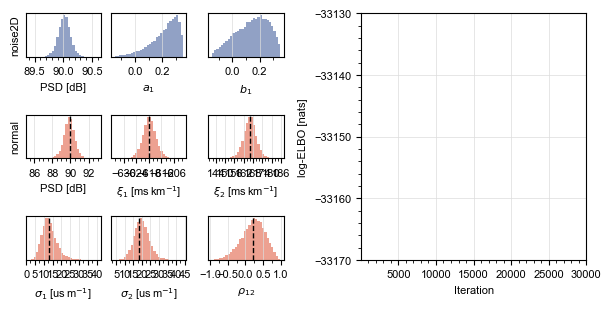

In [18]:
#__ Load true model for comparison __
m_true = np.loadtxt('../data/eg1/true_model.txt')

#__ Create figure and axes __
fig = plt.figure(figsize=(6,3), facecolor='white', layout='constrained')
gs  = GridSpec(figure=fig, nrows=3, ncols=6)
axs = [fig.add_subplot(gs[:,3:])]
axs.extend([fig.add_subplot(gs[0,j]) for j in range(3)])
axs.extend([fig.add_subplot(gs[1,j]) for j in range(3)])
axs.extend([fig.add_subplot(gs[2,j]) for j in range(3)])

#__ Labels __
for ax, xlab, ylab in zip(axs,
    [r"Iteration",   r"PSD [dB]", r"$a_1$", r"$b_1$", r"PSD [dB]", r"$\xi_1$ [ms$\,$km$^{-1}$]", r"$\xi_2$ [ms$\,$km$^{-1}$]", r"$\sigma_1$ [us$\,$m$^{-1}$]", r"$\sigma_2$ [us$\,$m$^{-1}$]", r"$\rho_{12}$"],
    [r"log-ELBO [nats]", r"noise2D", None, None, r"normal", None, None, None, None, None]
):
    if (xlab is not None): ax.set_xlabel(xlab, fontsize=small)
    if (ylab is not None): ax.set_ylabel(ylab, fontsize=small)

#__ Ticks __
for ax, xlims, ylims, xticks, yticks in zip(axs,
    [(1,N_iterations), None, None, None, None, None, None, None, None, None],
    [(-33170,-33130), None, None, None, None, None, None, None, None, None],
    [(5000,1000), (0.5,0.1), (0.2,0.1), (0.2,0.1), (2,0.5), (6,2), (6,2), (5,2.5), (5,2.5), (0.5,0.25)],
    [(10,2), None, None, None, None, None, None, None, None, None]
):
    if (xlims is not None): ax.set_xlim(*xlims)
    if (ylims is not None): ax.set_ylim(*ylims)
    if (xticks is not None):
        ax.xaxis.set_major_locator(ticker.MultipleLocator(xticks[0]))
        ax.xaxis.set_minor_locator(ticker.MultipleLocator(xticks[1]))
    else: ax.set_xticks([])
    if (yticks is not None):
        ax.yaxis.set_major_locator(ticker.MultipleLocator(yticks[0]))
        ax.yaxis.set_minor_locator(ticker.MultipleLocator(yticks[1]))
    else: ax.set_yticks([])
    ax.tick_params(labelsize=small)
    ax.grid(color='gainsboro', linewidth=0.5)

#__ Plot loss function __
axs[0].plot(1+np.arange(N_iterations), lnELBO, lw=1.0, c='k', zorder=1)

#__ Plot 'noise2D' parameter histograms __
scales = [1e0, 1e0, 1e0]
for mi, mi_true, ax, sc in zip(m.T[6:], m_true[6:], axs[1:4], scales):
    ax.hist(sc*mi, bins=30, color=theme[2], alpha=0.5, zorder=1)
    # ax.axvline(sc*mi_true, lw=1.0, ls='--', color='k', zorder=2)

#__ Plot 'normal' parameter histograms __
scales = [1e0, 1e6, 1e6, 1e6, 1e6, 1e0]
for mi, mi_true, ax, sc in zip(m.T[:6], m_true[:6], axs[4:], scales):
    ax.hist(sc*mi, bins=30, color=theme[0], alpha=0.5, zorder=1)
    ax.axvline(sc*mi_true, lw=1.0, ls='--', color='k', zorder=2)

#__ Show figure __
display(fig)
plt.close(fig)